# Задания 0–1. Исходные данные и разведочный анализ спроса

**ВКР:** «Вероятностное прогнозирование спроса и оптимизация закупок с использованием интеллектуального агента»
**Раздел ВКР:** 2.1 «Исходные данные»

Цель ноутбука — понять структуру спроса каждого SKU до моделирования и обосновать выбор признаков и распределения.

| № | Шаг | Результат |
|---|-----|-----------|
| 0 | Генерация и проверка данных | `data/sales.csv`, описание компонентов спроса |
| 1.1 | Спрос + скользящее среднее 28 дней | Рис. 1 |
| 1.2 | STL-декомпозиция SKU_A, SKU_B | Рис. 2–3 |
| 1.3 | Дни недели, месяцы, промо, праздники | Рис. 4, таблица эффектов |
| 1.4 | Проверка сверхдисперсии | Рис. 5, оценка $k$ |
| 1.5 | Классификация Syntetos–Boylan | Рис. 6, ADI и CV² |
| 1.6 | ACF / PACF для SKU_A | Рис. 7, выбор лагов |
| — | Сводная таблица и выводы | `reports/eda_summary.csv` |

In [1]:
from pathlib import Path
import subprocess, sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

SEED = 2026  # последние 4 цифры зачётной книжки (заменить и перезапустить)

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA = ROOT / "data" / "sales.csv"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# данные пересоздаются из скрипта Задания 0, чтобы ноутбук был воспроизводимым
subprocess.run([sys.executable, str(ROOT / "src" / "generate_data.py"),
                "--seed", str(SEED), "--out", str(DATA)], check=True)

df = pd.read_csv(DATA, parse_dates=["date"])
SKUS = sorted(df["sku"].unique())

# разбиение из задания: обучение 2023–2024, валидация янв–июн 2025, тест июл–дек 2025
TRAIN_END, VALID_END = pd.Timestamp("2024-12-31"), pd.Timestamp("2025-06-30")
df["split"] = np.select([df["date"] <= TRAIN_END, df["date"] <= VALID_END],
                        ["train", "valid"], "test")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
def savefig(name):
    plt.savefig(FIG / name, bbox_inches="tight", dpi=150)
df.head()

seed=2026: сохранено 5480 строк в /home/claude/repo/data/sales.csv


,date,sku,demand,price,promo,holiday,split
0,2023-01-01,SKU_A,23,1000.0,0,0,train
1,2023-01-02,SKU_A,17,1000.0,0,0,train
2,2023-01-03,SKU_A,27,1000.0,0,0,train
3,2023-01-04,SKU_A,38,1000.0,0,0,train
4,2023-01-05,SKU_A,9,1000.0,0,0,train


## Задание 0. Исходные данные

Данные синтетические: истинный закон спроса известен, поэтому можно проверить, насколько точно модели его восстанавливают.
Средний спрос SKU $i$ в день $t$ задаётся мультипликативной моделью

$$
\mu_{it} = (b_i + \beta_i t)\,\bigl(1 + s_i \sin\tfrac{2\pi(\text{doy}_t - 80)}{365{,}25}\bigr)\cdot w_{\text{dow}(t)}\cdot 1{,}6^{\text{promo}_{it}}\cdot 1{,}8^{\text{holiday}_t},
$$

а фактический спрос — отрицательное биномиальное распределение $D_{it}\sim\text{NB}(\mu_{it}, k=5)$ с дисперсией $\mu + \mu^2/k$.

**Компоненты спроса, заложенные в данные:**

1. **Уровень и линейный тренд** $b_i + \beta_i t$: SKU_A растёт (+0,010 ед./день), SKU_E падает (−0,008), SKU_C без тренда.
2. **Годовая сезонность** амплитуды $s_i$ (от 5 % у SKU_D до 40 % у SKU_B) с пиком около 21 июня (день 80 + четверть года).
3. **Недельная сезонность** $w$: пн 0,9 … сб 1,3, вс 1,2 — выходные выше будней.
4. **Промо** (≈5 % дней, случайно для каждого SKU): скидка 20 % и рост спроса в 1,6 раза.
5. **Праздники** (21 марта — Наурыз, 16 декабря — День Независимости, 31 декабря): рост в 1,8 раза.
6. **Цена**: 1000 ₸ с инфляцией 0,005 % в день, в промо −20 %.
7. **Случайность**: отрицательное биномиальное распределение (сверхдисперсия, $k=5$).
8. **Прерывистость** SKU_D: дополнительно 35 % дней продажи обнуляются.

In [2]:
print(f"Строк: {len(df)}, SKU: {len(SKUS)}, период: {df.date.min():%Y-%m-%d} — {df.date.max():%Y-%m-%d}")
print("Пропуски:", int(df.isna().sum().sum()), "| дубликаты (date, sku):", int(df.duplicated(["date", "sku"]).sum()))
print("\nЧисло дней в выборках (на один SKU):")
print(df[df.sku == "SKU_A"]["split"].value_counts().reindex(["train", "valid", "test"]).to_string())
df.groupby("sku")["demand"].describe().round(2)

Строк: 5480, SKU: 5, период: 2023-01-01 — 2025-12-31
Пропуски: 0 | дубликаты (date, sku): 0

Число дней в выборках (на один SKU):
split
train    731
valid    181
test     184


,count,mean,std,min,25%,50%,75%,max
sku,,,,,,,,
SKU_A,1096.0,49.51,27.36,2.0,29.75,44.0,64.0,208.0
SKU_B,1096.0,18.54,11.61,1.0,10.00,16.0,24.0,89.0
SKU_C,1096.0,8.55,5.25,0.0,5.00,8.0,11.0,39.0
SKU_D,1096.0,2.41,2.82,0.0,0.00,2.0,4.0,19.0
SKU_E,1096.0,60.97,32.45,8.0,38.00,55.0,77.0,227.0


## 1.1. Динамика спроса и скользящее среднее за 28 дней
Пунктирные линии — границы обучающей, валидационной и тестовой выборок.

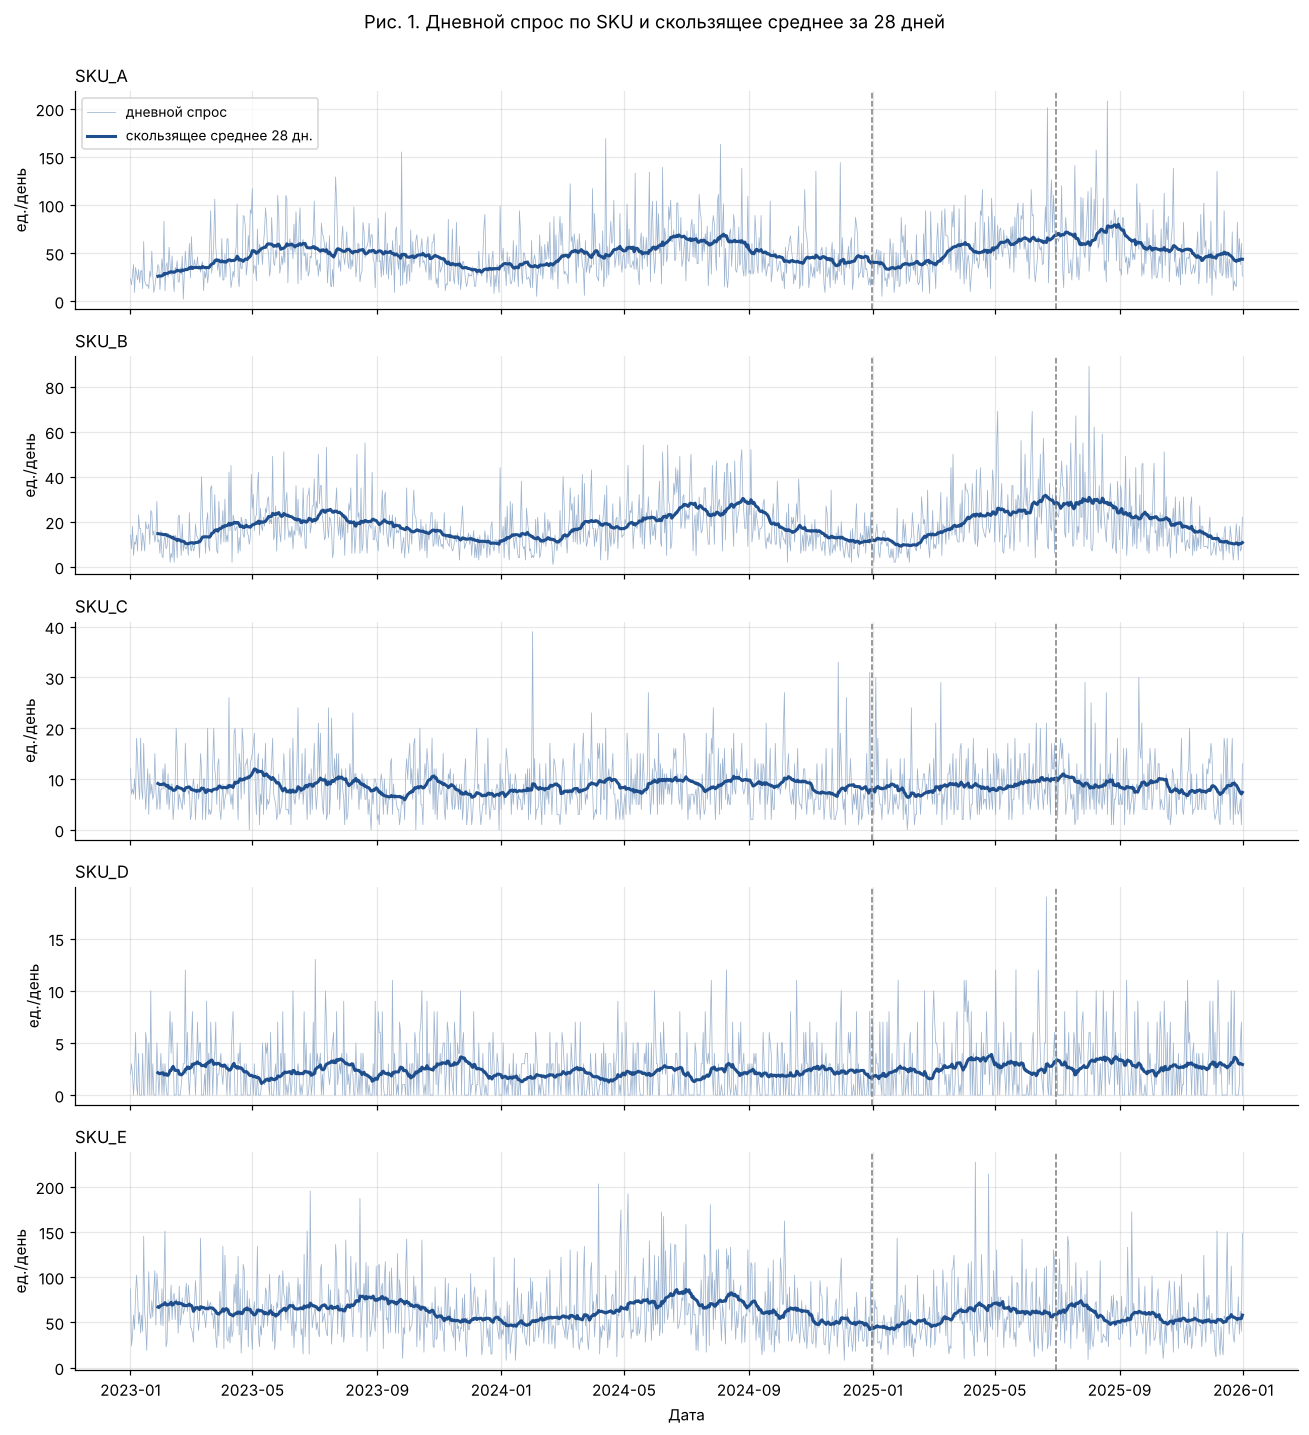

In [3]:
fig, axes = plt.subplots(len(SKUS), 1, figsize=(12, 13), sharex=True)
for ax, sku in zip(axes, SKUS):
    s = df[df.sku == sku].set_index("date")["demand"]
    ax.plot(s.index, s, lw=0.5, color="#9db4d0", label="дневной спрос")
    ax.plot(s.index, s.rolling(28).mean(), lw=2, color="#1f4e8c", label="скользящее среднее 28 дн.")
    for b in (TRAIN_END, VALID_END):
        ax.axvline(b, color="grey", ls="--", lw=1)
    ax.set_title(sku, loc="left", fontsize=11)
    ax.set_ylabel("ед./день")
axes[0].legend(loc="upper left", fontsize=9)
axes[-1].set_xlabel("Дата")
fig.suptitle("Рис. 1. Дневной спрос по SKU и скользящее среднее за 28 дней", y=1.0)
plt.tight_layout(); savefig("fig1_demand_rolling.png"); plt.show()

## 1.2. STL-декомпозиция (SKU_A и SKU_B)
`period=7` выделяет недельную сезонность; годовая волна при этом остаётся в компоненте тренда.
Сила компоненты считается по Hyndman & Athanasopoulos (FPP3, гл. 3): $F_S = \max\bigl(0,\,1-\tfrac{\operatorname{Var}(R)}{\operatorname{Var}(S+R)}\bigr)$, аналогично $F_T$ для тренда.

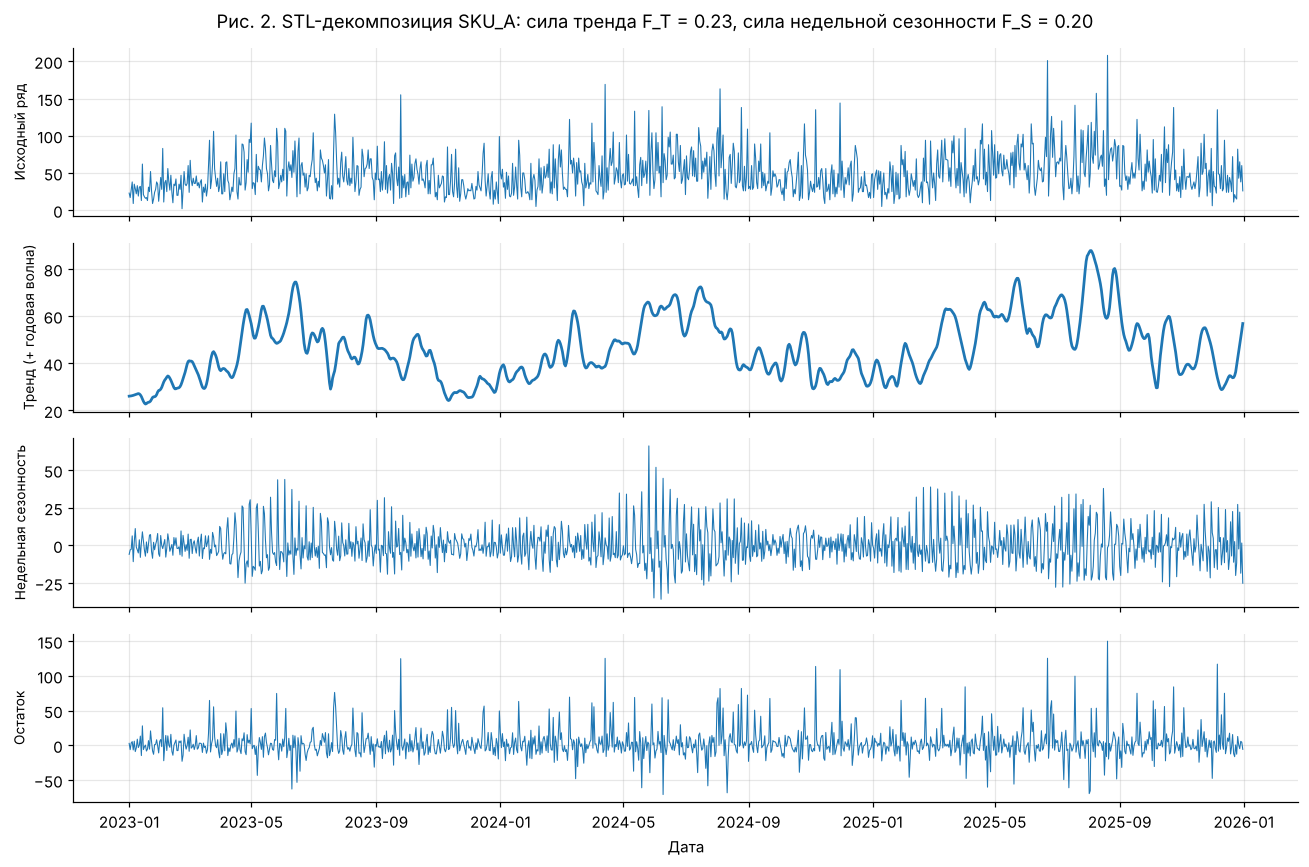

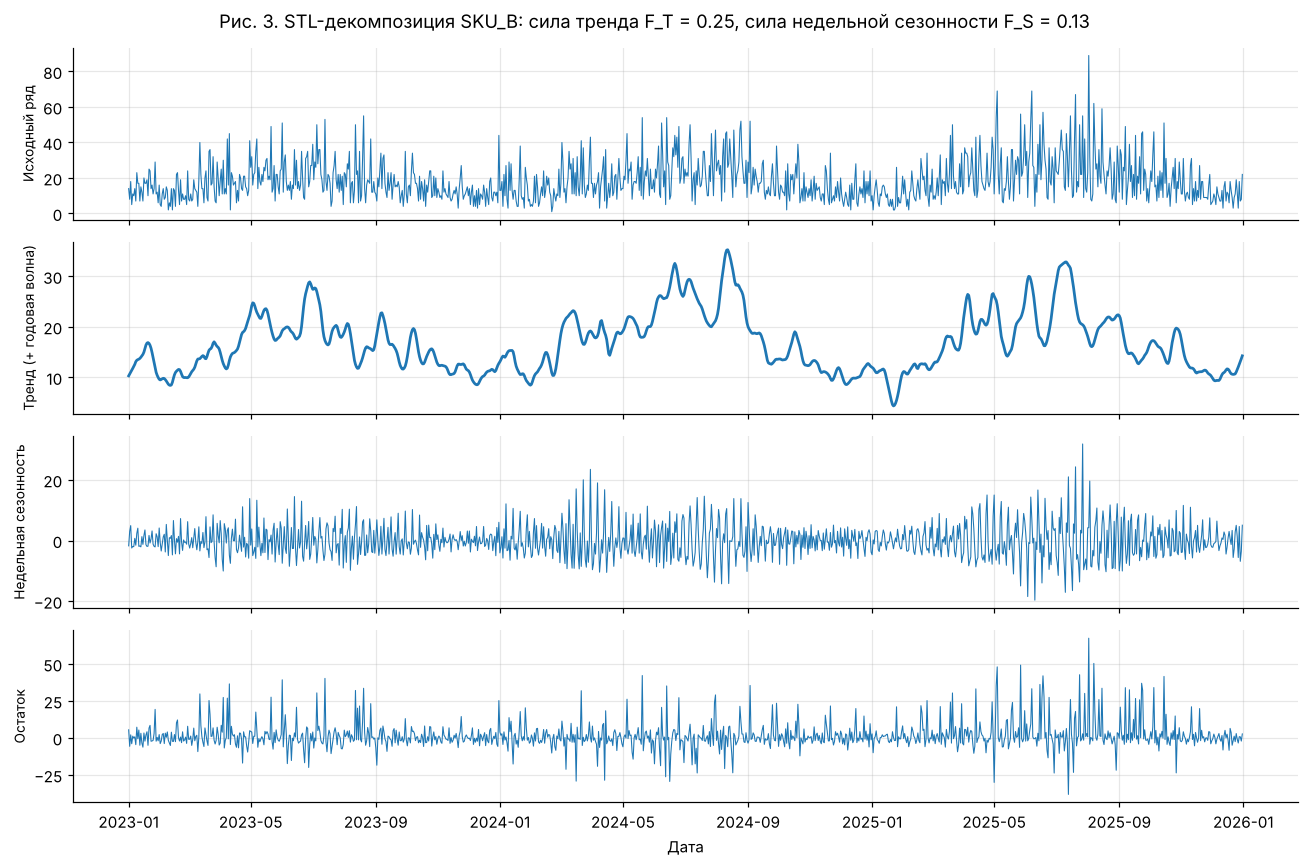

In [4]:
stl_strength = {}
for i, sku in enumerate(["SKU_A", "SKU_B"], start=2):
    s = df[df.sku == sku].set_index("date")["demand"].asfreq("D")
    res = STL(s, period=7, robust=True).fit()
    F_T = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
    F_S = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    stl_strength[sku] = (F_T, F_S)
    fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    for a, (comp, name) in zip(ax, [(s, "Исходный ряд"), (res.trend, "Тренд (+ годовая волна)"),
                                    (res.seasonal, "Недельная сезонность"), (res.resid, "Остаток")]):
        a.plot(comp.index, comp, lw=0.7 if name != "Тренд (+ годовая волна)" else 1.8)
        a.set_ylabel(name, fontsize=9)
    ax[-1].set_xlabel("Дата")
    fig.suptitle(f"Рис. {i}. STL-декомпозиция {sku}: сила тренда F_T = {F_T:.2f}, "
                 f"сила недельной сезонности F_S = {F_S:.2f}")
    plt.tight_layout(); savefig(f"fig{i}_stl_{sku}.png"); plt.show()

## 1.3. Дни недели, месяцы, эффект промо и праздников
Средний спрос по дню недели и месяцу нормирован на средний спрос SKU (индекс 1,0 = среднее), чтобы товары разного масштаба были на одном графике.
Эффект промо и праздников — отношение средних: $\bar y_{\text{promo}=1} / \bar y_{\text{promo}=0}$.

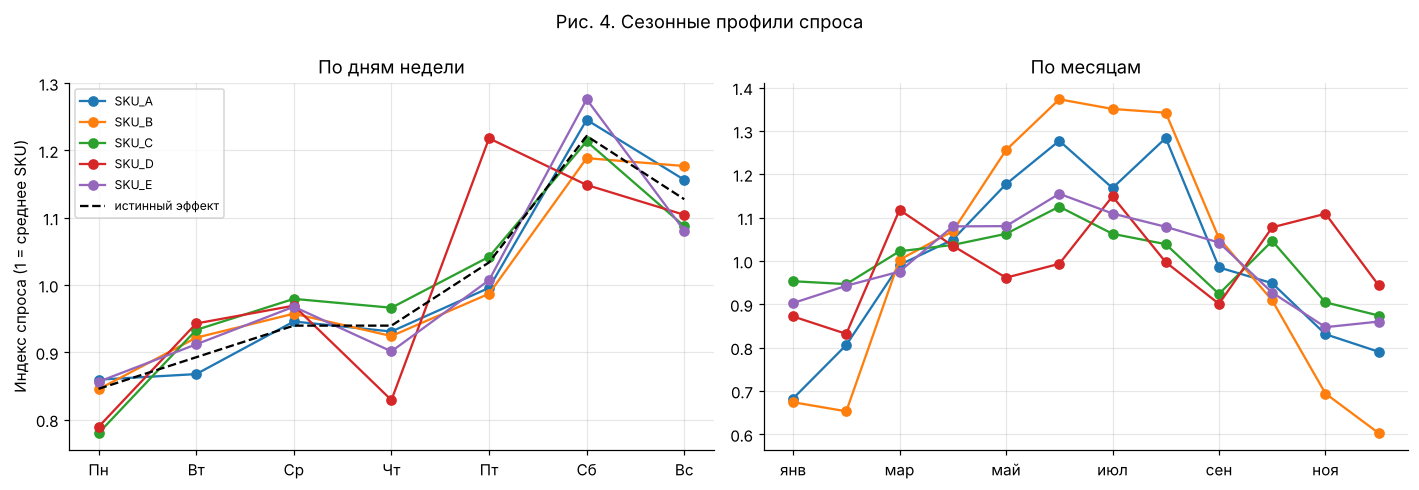

Истинные значения: промо 1.6, праздник 1.8. Праздничных дней всего 9, и все они зимой/весной,
поэтому сырое отношение средних занижено сезонным спадом; «эффект …» — оценка с поправкой.


,"промо, сырое",эффект промо,"праздник, сырое",эффект праздника,дней промо
sku,,,,,
SKU_A,1.53,1.58,1.35,1.77,44
SKU_B,1.35,1.46,1.53,2.06,44
SKU_C,1.59,1.66,1.34,1.62,55
SKU_D,1.18,1.35,0.69,0.99,66
SKU_E,1.60,1.59,1.36,1.62,59


In [5]:
DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
MON = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
d = df.assign(dow=df.date.dt.dayofweek, month=df.date.dt.month)
sku_mean = d.groupby("sku")["demand"].transform("mean")
d["idx"] = d["demand"] / sku_mean

dow_idx = d.groupby(["dow", "sku"])["idx"].mean().unstack()
mon_idx = d.groupby(["month", "sku"])["idx"].mean().unstack()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dow_idx.index = DOW; dow_idx.plot(ax=ax[0], marker="o")
ax[0].plot(DOW, [0.9, 0.95, 1.0, 1.0, 1.1, 1.3, 1.2] / np.mean([0.9, 0.95, 1.0, 1.0, 1.1, 1.3, 1.2]),
           "k--", lw=1.5, label="истинный эффект")
ax[0].set_title("По дням недели"); ax[0].set_ylabel("Индекс спроса (1 = среднее SKU)"); ax[0].set_xlabel("")
ax[0].legend(fontsize=8)
mon_idx.index = MON; mon_idx.plot(ax=ax[1], marker="o", legend=False)
ax[1].set_title("По месяцам"); ax[1].set_xlabel("")
fig.suptitle("Рис. 4. Сезонные профили спроса")
plt.tight_layout(); savefig("fig4_dow_month.png"); plt.show()

def ratio(g, col):
    m = g.groupby(col)["demand"].mean()
    return m.get(1, np.nan) / m.get(0, np.nan)

# Поправка на сезонность: делим спрос на «базовый уровень» — центрированное скользящее
# среднее за 29 дней, посчитанное только по обычным дням (без промо и праздников).
def adj_ratio(g, col):
    g = g.sort_values("date")
    regular = g["demand"].where((g.promo == 0) & (g.holiday == 0))
    base = regular.rolling(29, center=True, min_periods=10).mean()
    rel = g["demand"] / base
    return rel[g[col] == 1].mean() / rel[(g.promo == 0) & (g.holiday == 0)].mean()

by = df.groupby("sku")
effects = pd.DataFrame({
    "промо, сырое": by.apply(ratio, "promo", include_groups=False),
    "эффект промо": by.apply(adj_ratio, "promo", include_groups=False),
    "праздник, сырое": by.apply(ratio, "holiday", include_groups=False),
    "эффект праздника": by.apply(adj_ratio, "holiday", include_groups=False),
    "дней промо": by["promo"].sum(),
}).round(2)
print("Истинные значения: промо 1.6, праздник 1.8. Праздничных дней всего 9, и все они зимой/весной,")
print("поэтому сырое отношение средних занижено сезонным спадом; «эффект …» — оценка с поправкой.")
effects

## 1.4. Проверка сверхдисперсии
Для распределения Пуассона $\operatorname{Var}(D) = \mu$, для отрицательного биномиального $\operatorname{Var}(D) = \mu + \mu^2/k$.
Считаем среднее и дисперсию спроса в скользящих окнах по 28 дней и сравниваем с обеими линиями.
Параметр $k$ оцениваем МНК через начало координат: $\operatorname{Var} - \mu = \mu^2 / k \Rightarrow \hat{(1/k)} = \sum \mu^2(\operatorname{Var}-\mu) / \sum \mu^4$.

> Внутри окна средний спрос не постоянен (день недели, промо), поэтому часть «лишней» дисперсии вызвана сезонностью. Оценка $\hat k$ получается **ниже** истинной $k=5$ — это ожидаемо; точную оценку даст NB-GLM с признаками в Задании 3.

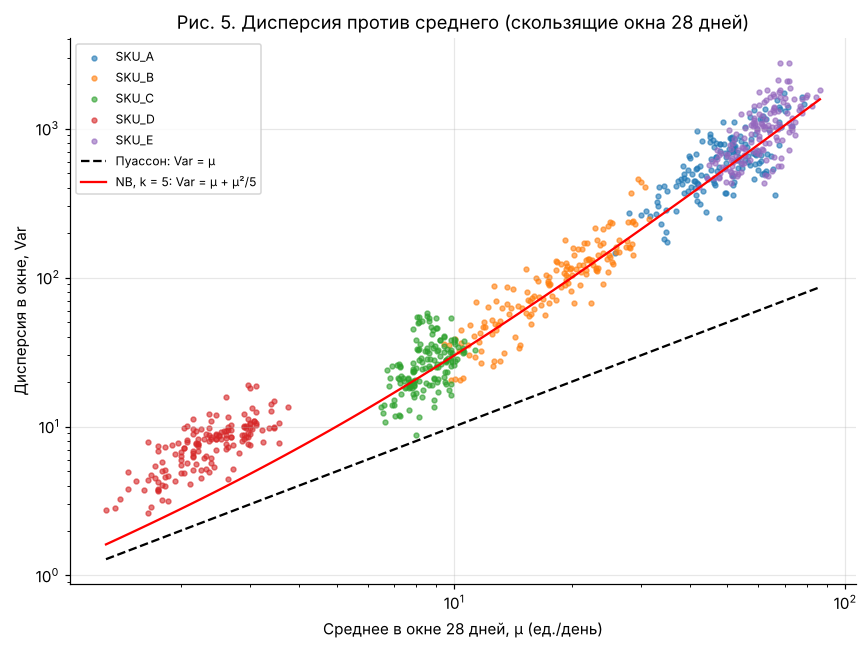

,Var/mean (медиана по окнам),доля окон с Var > mean,оценка k
sku,,,
SKU_A,11.85,1.0,4.39
SKU_B,5.14,1.0,4.15
SKU_C,2.95,1.0,3.99
SKU_D,3.22,1.0,1.16
SKU_E,14.88,1.0,4.04


In [6]:
disp_rows, pts = [], []
for sku in SKUS:
    s = df[df.sku == sku].set_index("date")["demand"]
    r = pd.DataFrame({"m": s.rolling(28).mean(), "v": s.rolling(28).var()}).dropna().iloc[::7]
    inv_k = (r.m**2 * (r.v - r.m)).sum() / (r.m**4).sum()
    disp_rows.append({"sku": sku, "Var/mean (медиана по окнам)": (r.v / r.m).median(),
                      "доля окон с Var > mean": (r.v > r.m).mean(),
                      "оценка k": 1 / inv_k if inv_k > 0 else np.inf})
    pts.append(r.assign(sku=sku))
disp = pd.DataFrame(disp_rows).set_index("sku").round(2)
pts = pd.concat(pts)

fig, ax = plt.subplots(figsize=(8, 6))
for sku, g in pts.groupby("sku"):
    ax.scatter(g.m, g.v, s=10, alpha=0.6, label=sku)
grid = np.logspace(np.log10(pts.m.min()), np.log10(pts.m.max()), 100)
ax.plot(grid, grid, "k--", lw=1.5, label="Пуассон: Var = μ")
ax.plot(grid, grid + grid**2 / 5, "r-", lw=1.5, label="NB, k = 5: Var = μ + μ²/5")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Среднее в окне 28 дней, μ (ед./день)"); ax.set_ylabel("Дисперсия в окне, Var")
ax.set_title("Рис. 5. Дисперсия против среднего (скользящие окна 28 дней)")
ax.legend(fontsize=8)
plt.tight_layout(); savefig("fig5_overdispersion.png"); plt.show()
disp

## 1.5. Классификация спроса по Syntetos–Boylan
- **ADI** (average demand interval) — среднее число дней между ненулевыми продажами: $\text{ADI} = N_{\text{дней}} / N_{\text{дней с продажами}}$.
- **CV²** — квадрат коэффициента вариации *ненулевых* продаж: $\text{CV}^2 = (\sigma_{+}/\mu_{+})^2$.

| | CV² < 0,49 | CV² ≥ 0,49 |
|---|---|---|
| **ADI < 1,32** | Smooth (регулярный) | Erratic (неустойчивый) |
| **ADI ≥ 1,32** | Intermittent (прерывистый) | Lumpy (комковатый) |

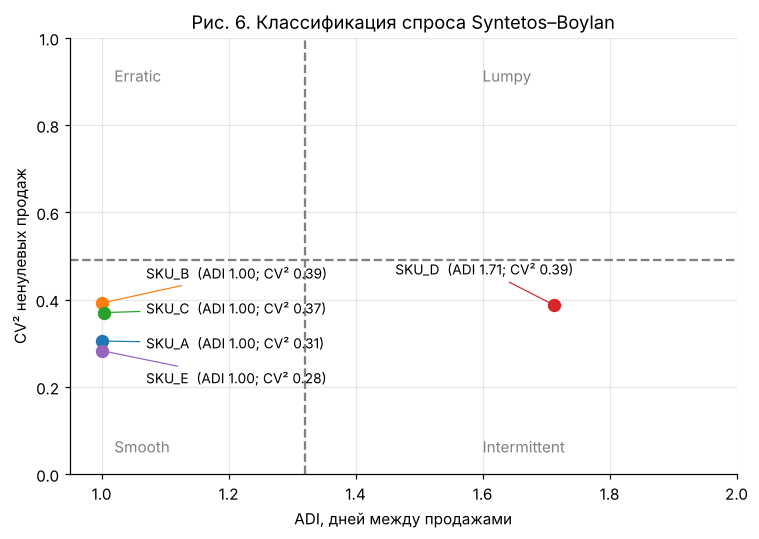

,доля нулей,ADI,CV²,класс
sku,,,,
SKU_A,0.000,1.000,0.305,smooth
SKU_B,0.000,1.000,0.392,smooth
SKU_C,0.005,1.005,0.371,smooth
SKU_D,0.416,1.712,0.388,intermittent
SKU_E,0.000,1.000,0.283,smooth


In [7]:
def sb_class(adi, cv2):
    if adi < 1.32:
        return "smooth" if cv2 < 0.49 else "erratic"
    return "intermittent" if cv2 < 0.49 else "lumpy"

sb = []
for sku in SKUS:
    y = df[df.sku == sku]["demand"].to_numpy()
    nz = y[y > 0]
    adi = len(y) / len(nz)
    cv2 = (nz.std(ddof=1) / nz.mean()) ** 2
    sb.append({"sku": sku, "доля нулей": (y == 0).mean(), "ADI": adi, "CV²": cv2, "класс": sb_class(adi, cv2)})
sb = pd.DataFrame(sb).set_index("sku")

fig, ax = plt.subplots(figsize=(7, 5))
ax.axvline(1.32, color="grey", ls="--"); ax.axhline(0.49, color="grey", ls="--")
colors = dict(zip(SKUS, plt.cm.tab10.colors))
left = sb[sb.ADI < 1.32].sort_values("CV²", ascending=False)
label_y = dict(zip(left.index, np.linspace(0.46, 0.22, len(left))))  # разносим подписи, чтобы не налезали
for sku, r in sb.iterrows():
    ax.scatter(r.ADI, r["CV²"], s=60, color=colors[sku], zorder=3)
    txt = f"{sku}  (ADI {r.ADI:.2f}; CV² {r['CV²']:.2f})"
    if sku in label_y:
        ax.annotate(txt, (r.ADI, r["CV²"]), xytext=(1.07, label_y[sku]), fontsize=9, va="center",
                    arrowprops=dict(arrowstyle="-", color=colors[sku], lw=0.8))
    else:
        ax.annotate(txt, (r.ADI, r["CV²"]), xytext=(r.ADI - 0.25, r["CV²"] + 0.07), fontsize=9,
                    arrowprops=dict(arrowstyle="-", color=colors[sku], lw=0.8))
for (x, y, t) in [(1.02, 0.05, "Smooth"), (1.02, 0.9, "Erratic"), (1.6, 0.05, "Intermittent"), (1.6, 0.9, "Lumpy")]:
    ax.text(x, y, t, color="grey", fontsize=10)
ax.set_xlim(0.95, max(2.0, sb.ADI.max() + 0.2)); ax.set_ylim(0, max(1.0, sb["CV²"].max() + 0.1))
ax.set_xlabel("ADI, дней между продажами"); ax.set_ylabel("CV² ненулевых продаж")
ax.set_title("Рис. 6. Классификация спроса Syntetos–Boylan")
plt.tight_layout(); savefig("fig6_syntetos_boylan.png"); plt.show()
sb.round(3)

## 1.6. ACF и PACF для SKU_A
Строим на обучающей выборке (2023–2024), чтобы не заглядывать в будущее. Горизонт прогноза — 7 дней, поэтому для признаков годятся только лаги ≥ 7.

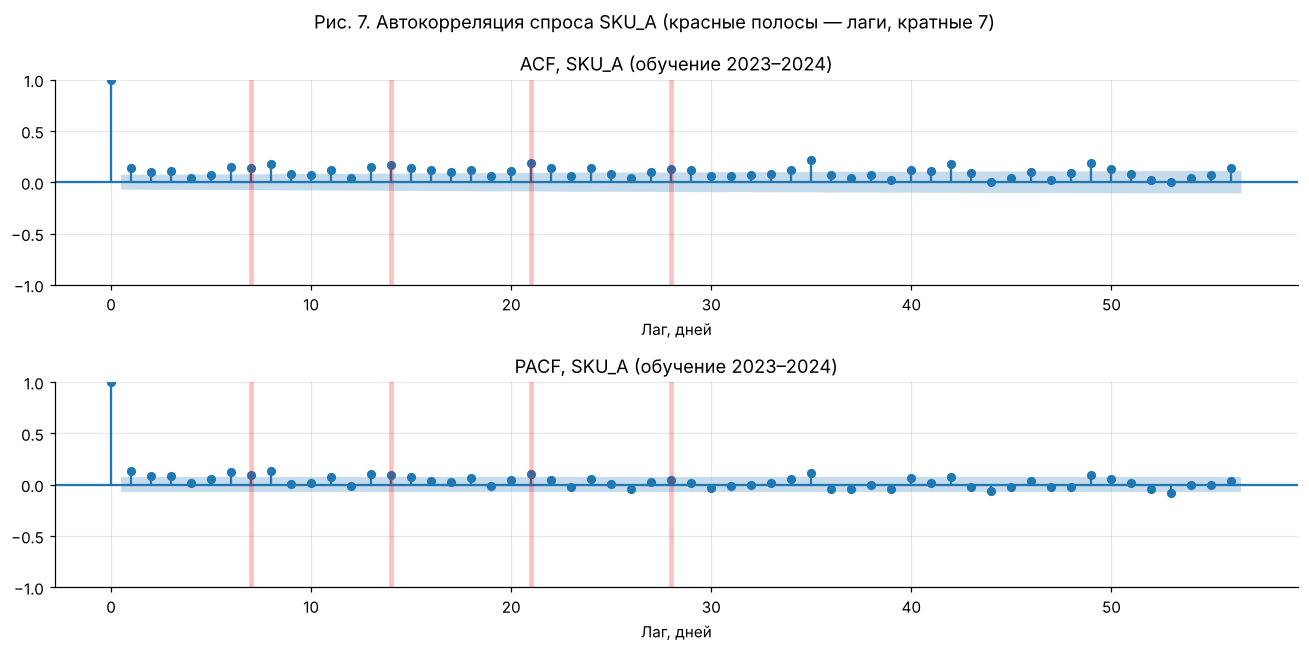

Граница значимости ±0.072
ACF на лагах 1, 7, 14, 21, 28: {1: 0.136, 7: 0.137, 14: 0.17, 21: 0.186, 28: 0.131}
Значимые лаги PACF: [1, 2, 3, 6, 7, 8, 11, 13, 14, 21, 35, 42, 49, 53]


In [8]:
y_tr = df[(df.sku == "SKU_A") & (df.split == "train")]["demand"].to_numpy()
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(y_tr, lags=56, ax=ax[0], title="ACF, SKU_A (обучение 2023–2024)")
plot_pacf(y_tr, lags=56, ax=ax[1], method="ywm", title="PACF, SKU_A (обучение 2023–2024)")
for a in ax:
    for L in (7, 14, 21, 28):
        a.axvline(L, color="red", alpha=0.25, lw=3)
    a.set_xlabel("Лаг, дней")
fig.suptitle("Рис. 7. Автокорреляция спроса SKU_A (красные полосы — лаги, кратные 7)")
plt.tight_layout(); savefig("fig7_acf_pacf_SKU_A.png"); plt.show()

conf = 1.96 / np.sqrt(len(y_tr))
acf_v, pacf_v = acf(y_tr, nlags=56), pacf(y_tr, nlags=56, method="ywm")
print(f"Граница значимости ±{conf:.3f}")
print("ACF на лагах 1, 7, 14, 21, 28:", {L: round(float(acf_v[L]), 3) for L in (1, 7, 14, 21, 28)})
sig_pacf = [L for L in range(1, 57) if abs(pacf_v[L]) > conf]
print("Значимые лаги PACF:", sig_pacf)

## Сводная таблица по SKU

In [9]:
summary = (df.groupby("sku")["demand"].agg(среднее="mean", ст_откл="std")
           .join(sb[["ADI", "CV²", "класс"]])
           .join(effects[["эффект промо", "эффект праздника"]])
           .join(disp[["оценка k"]]))
summary.insert(2, "CV", summary["ст_откл"] / summary["среднее"])
summary = summary.round(3)
summary.to_csv(ROOT / "reports" / "eda_summary.csv", encoding="utf-8-sig")
summary

,среднее,ст_откл,CV,ADI,CV²,класс,эффект промо,эффект праздника,оценка k
sku,,,,,,,,,
SKU_A,49.514,27.358,0.553,1.000,0.305,smooth,1.58,1.77,4.39
SKU_B,18.542,11.612,0.626,1.000,0.392,smooth,1.46,2.06,4.15
SKU_C,8.552,5.249,0.614,1.005,0.371,smooth,1.66,1.62,3.99
SKU_D,2.405,2.822,1.173,1.712,0.388,intermittent,1.35,0.99,1.16
SKU_E,60.970,32.452,0.532,1.000,0.283,smooth,1.59,1.62,4.04


## Выводы
Выводы формируются из рассчитанных чисел, поэтому при смене `SEED` они обновятся автоматически.

In [10]:
a = summary.loc["SKU_A"]; dd = summary.loc["SKU_D"]
wk = dow_idx.loc["Сб"].mean() / dow_idx.loc["Пн"].mean()
F_T, F_S = stl_strength["SKU_A"]
print(f"1. Сезонность и тренд. Спрос в субботу в среднем в {wk:.2f} раза выше, чем в понедельник "
      f"(заложено 1.3/0.9 = 1.44); годовая волна видна на рис. 1 и 4. При этом у SKU_A сила недельной "
      f"сезонности F_S = {F_S:.2f} и тренда F_T = {F_T:.2f} — случайная составляющая преобладает, "
      f"поэтому точечного прогноза мало и нужен вероятностный. День недели и месяц — обязательные признаки.")
print(f"2. Промо увеличивает спрос в {effects['эффект промо'].min():.2f}–{effects['эффект промо'].max():.2f} раза "
      f"(истина 1.6), праздники — в {effects['эффект праздника'].min():.2f}–{effects['эффект праздника'].max():.2f} раза "
      f"(истина 1.8, всего 9 дней — оценка шумная). Без поправки на сезонность эффект праздника занижается "
      f"до {effects['праздник, сырое'].min():.2f}–{effects['праздник, сырое'].max():.2f}. Признаки promo и holiday обязательны.")
share = disp.iloc[:, 1].min()
k_reg = disp.drop("SKU_D")["оценка k"]
print(f"3. Сверхдисперсия. Медианное отношение Var/mean в окнах 28 дней — от {disp.iloc[:,0].min():.1f} "
      f"до {disp.iloc[:,0].max():.1f} при 1.0 у Пуассона; Var > mean "
      f"{'во всех окнах' if share == 1 else f'в {share:.0%} окон'}. Пуассон не подходит — выбираем "
      f"отрицательное биномиальное. Оценка k для SKU_A–C, E: {k_reg.min():.1f}–{k_reg.max():.1f} "
      f"(истина 5; занижена из-за сезонности внутри окна), у SKU_D k = {disp.loc['SKU_D','оценка k']:.1f} "
      f"из-за дополнительных нулей.")
print(f"4. Прерывистость. SKU_D: доля нулевых дней {sb.loc['SKU_D','доля нулей']:.0%}, ADI = {dd['ADI']:.2f} "
      f"(> 1.32), CV² = {dd['CV²']:.2f} → класс «{dd['класс']}». Для него нужен метод Кростона/SBA "
      f"и нельзя использовать MAPE. Остальные SKU: класс «{summary.drop('SKU_D')['класс'].unique()[0]}».")
weekly = [L for L in sig_pacf if L % 7 == 0]
print(f"5. Лаги. ACF SKU_A положительна и медленно убывает (на лагах 7/14/21/28: "
      f"{', '.join(f'{acf_v[L]:.2f}' for L in (7, 14, 21, 28))}) — след тренда и годовой волны. "
      f"PACF значима на лагах, кратных неделе: {weekly}. Короткие лаги 1–6 тоже значимы, но при горизонте "
      f"7 дней недоступны, поэтому берём лаги 7, 14, 21, 28 и скользящие среднее/ст. отклонение со сдвигом 7.")

1. Сезонность и тренд. Спрос в субботу в среднем в 1.47 раза выше, чем в понедельник (заложено 1.3/0.9 = 1.44); годовая волна видна на рис. 1 и 4. При этом у SKU_A сила недельной сезонности F_S = 0.20 и тренда F_T = 0.23 — случайная составляющая преобладает, поэтому точечного прогноза мало и нужен вероятностный. День недели и месяц — обязательные признаки.
2. Промо увеличивает спрос в 1.35–1.66 раза (истина 1.6), праздники — в 0.99–2.06 раза (истина 1.8, всего 9 дней — оценка шумная). Без поправки на сезонность эффект праздника занижается до 0.69–1.53. Признаки promo и holiday обязательны.
3. Сверхдисперсия. Медианное отношение Var/mean в окнах 28 дней — от 3.0 до 14.9 при 1.0 у Пуассона; Var > mean во всех окнах. Пуассон не подходит — выбираем отрицательное биномиальное. Оценка k для SKU_A–C, E: 4.0–4.4 (истина 5; занижена из-за сезонности внутри окна), у SKU_D k = 1.2 из-за дополнительных нулей.
4. Прерывистость. SKU_D: доля нулевых дней 42%, ADI = 1.71 (> 1.32), CV² = 0.39 → класс «

## Что дальше
- **Задание 2** — базовые точечные прогнозы (сезонная наивная, Хольт–Винтерс, Кростон/SBA для SKU_D) со скользящим происхождением на валидации.
- **Задание 3** — вероятностный прогноз: квантильный LightGBM и NB-GLM; сравнить оценённое $k$ с истинным $k=5$.